# Open question: does Wikipedia attention match IMDb popularity?

## The question

**For the films enriched in `IMDb_Data_Enrichment.ipynb` (top 10 per genre and year, 1980–2025), how closely does the attention a film gets on Wikipedia follow its popularity on IMDb, how does this differ by genre and decade, and which films are much more, or much less, present on Wikipedia than their IMDb popularity predicts?**

## Methodology

1. **Join (Spark):** enriched films (IMDb votes, rating, genres, year) ⋈ Wikidata item ⋈ English article ⋈ monthly page views ⋈ article size ⋈ sitelinks.
2. **Measures:**
   - `views_12m`: page views over the last 12 complete months. Recent attention is comparable across films of any age, while the all-time total would favour films released after 2015.
   - `views_per_1k_votes`: Wikipedia attention per unit of IMDb popularity.
3. **Rank (Spearman) correlations** between IMDb votes and each Wikipedia measure, overall and per genre and decade. Ranks are used because both votes and views are extremely skewed, so a few blockbusters would dominate a Pearson correlation.
4. **Expected attention:** a least-squares line of `log10(views_12m)` on `log10(numVotes)`, fitted with Spark aggregates. Each film's **residual** is how many orders of magnitude more (positive) or less (negative) it is viewed than films with the same number of votes. The same is done for article size, to find popular but under-documented films.
5. **Genre and decade comparison** of the medians and of the share of films far above or below the line (|residual| > 0.5, i.e. more than ×3 or less than ÷3 the expected views).

**Alternatives considered:**

- **Wikipedia edit counts:** edits count correlates more with legal/opinions disputes and not overlall likeness of the movie.
- **Google Trends:** they forbid automated collection.
- **Pearson correlation on raw counts:** too sensitive to the few films with millions of views.
- **A full regression with genre and decade as covariates** :Possibly to time consuming to train and / or les readable data

## 1. Setup

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display
from pyspark.sql import SparkSession, functions as F, types as T

import wikimedia_client as wc

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 80)

SPARK_DATA_DIR = Path(os.environ.get("SPARK_DATA_DIR", "spark_data"))
MAX_ROWS = int(os.environ.get("MAX_ROWS", "3000"))
RUN_NAME = "full" if MAX_ROWS < 0 else f"sample_{MAX_ROWS}"
WORK_DIR = SPARK_DATA_DIR / RUN_NAME
OUTPUT_DIR = Path("results") / RUN_NAME / "open_question"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RAW_DIR = Path("enrichment_raw")

PAGEVIEWS_REQUEST_INTERVAL_SECONDS = 0.1
OTHER_REQUEST_INTERVAL_SECONDS = 1.0
MIN_GROUP_SIZE = 30
OUTLIER_RESIDUAL = 0.5

spark = (
    SparkSession.builder
    .appName("imdb-open-question-wikipedia-attention")
    .master("local[*]")
    .config("spark.driver.memory", os.environ.get("SPARK_DRIVER_MEMORY", "4g"))
    .config("spark.sql.shuffle.partitions", "16")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("WARN")
print(f"Run mode: {RUN_NAME}, results in {OUTPUT_DIR}/")


def export(df, filename, n=20):
    pdf = df.toPandas()
    display(pdf.head(n))
    pdf.to_csv(OUTPUT_DIR / filename, index=False)
    return pdf

Run mode: sample_3000, results in results/sample_3000/open_question/


## 2. Load the enriched films

In [2]:
for table in ["films_to_enrich", "wikidata_films_clean", "wikipedia_films_clean"]:
    path = WORK_DIR / "enrichment" / table
    if not (path / "_SUCCESS").exists():
        raise FileNotFoundError(f"{path} is missing. Run IMDb_Data_Enrichment.ipynb first with MAX_ROWS = {MAX_ROWS}.")
    spark.read.parquet(str(path)).createOrReplaceTempView(table)

film_articles = spark.sql('''
SELECT f.tconst, f.primaryTitle, f.startYear, f.genres, f.averageRating, f.numVotes,
       w.wikidata_id, w.wikipedia_url, p.resolved_title
FROM films_to_enrich f
JOIN wikidata_films_clean w ON w.imdb_id = f.tconst
JOIN wikipedia_films_clean p ON p.wikipedia_url = w.wikipedia_url
WHERE w.wikipedia_url IS NOT NULL AND NOT p.missing
''').cache()
film_articles.createOrReplaceTempView("film_articles")
print(f"Enriched films with an English Wikipedia article: {film_articles.count():,}")

Enriched films with an English Wikipedia article: 2,090


## 3. Gather page views, article size and language editions (outside Spark)

Page views use one request per article. The Pageviews API serves cached aggregate data and documents a limit of 100 requests per second, so the default here is 10 requests per second, one at a time. The other two APIs keep the 1-second interval of the enrichment notebook. Already downloaded articles are skipped.

In [3]:
urls = sorted(r.wikipedia_url for r in film_articles.select("wikipedia_url").distinct().collect())
qids = sorted(r.wikidata_id for r in film_articles.select("wikidata_id").distinct().collect())
for name in ["pageviews_films", "article_info_films", "sitelinks_films"]:
    (RAW_DIR / f"{name}.jsonl").parent.mkdir(parents=True, exist_ok=True)
    (RAW_DIR / f"{name}.jsonl").touch()

fast_client = wc.RateLimitedSession(min_interval=PAGEVIEWS_REQUEST_INTERVAL_SECONDS)
slow_client = wc.RateLimitedSession(min_interval=OTHER_REQUEST_INTERVAL_SECONDS)
wc.collect(wc.JsonlStore(RAW_DIR / "pageviews_films.jsonl", key="wikipedia_url"), urls,
           lambda batch: wc.pageviews_monthly(fast_client, batch), 25, "Page views", progress_every=20)
wc.collect(wc.JsonlStore(RAW_DIR / "article_info_films.jsonl", key="wikipedia_url"), urls,
           lambda batch: wc.wikipedia_article_info(slow_client, batch), 50, "Article size")
wc.collect(wc.JsonlStore(RAW_DIR / "sitelinks_films.jsonl", key="wikidata_id"), qids,
           lambda batch: wc.wikidata_sitelinks(slow_client, batch), 200, "Language editions")
print(f"HTTP requests sent in this run: {fast_client.request_count + slow_client.request_count:,}")

Page views: 2,090 requested, 0 already cached, 2,090 to fetch


  Page views: 500/2,090


  Page views: 1,000/2,090


  Page views: 1,500/2,090


  Page views: 2,000/2,090


Article size: 2,090 requested, 0 already cached, 2,090 to fetch


... (3 outputs left out)

  Article size: 2,000/2,090


Language editions: 2,090 requested, 0 already cached, 2,090 to fetch


  Language editions: 2,000/2,090


HTTP requests sent in this run: 2,144


## 4. Clean and join in Spark

In [4]:
PAGEVIEW_SCHEMA = "wikipedia_url string, month string, views long, source_url string, retrieved_at timestamp, source string, license string"
INFO_SCHEMA = ("wikipedia_url string, resolved_title string, article_bytes long, last_revision_id long, "
               "source_url string, retrieved_at timestamp, source string, license string")
SITELINK_SCHEMA = "wikidata_id string, sitelinks int, source_url string, retrieved_at timestamp, source string, license string"

pageviews = (spark.read.schema(PAGEVIEW_SCHEMA).json(str(RAW_DIR / "pageviews_films.jsonl"))
             .where(F.col("month").rlike(r"^\d{6}$") & (F.col("views") >= 0))
             .dropDuplicates(["wikipedia_url", "month"]))
last_month = pageviews.agg(F.max("month")).first()[0]
first_month_12m = (pd.Timestamp(f"{last_month}01") - pd.DateOffset(months=11)).strftime("%Y%m") if last_month else None
print(f"Page views available up to {last_month}; last 12 months = {first_month_12m}..{last_month}")

pageviews.createOrReplaceTempView("pageviews")
(spark.read.schema(INFO_SCHEMA).json(str(RAW_DIR / "article_info_films.jsonl"))
    .where(F.col("article_bytes") > 0).dropDuplicates(["wikipedia_url"]).createOrReplaceTempView("article_info"))
(spark.read.schema(SITELINK_SCHEMA).json(str(RAW_DIR / "sitelinks_films.jsonl"))
    .where(F.col("sitelinks") >= 0).dropDuplicates(["wikidata_id"]).createOrReplaceTempView("sitelinks"))

attention = spark.sql(f'''
WITH views AS (
    SELECT wikipedia_url,
           SUM(CASE WHEN month BETWEEN '{first_month_12m}' AND '{last_month}' THEN views ELSE 0 END) AS views_12m,
           SUM(views) AS views_since_2015,
           COUNT(*) AS months_with_data,
           FIRST(source_url) AS pageviews_source_url
    FROM pageviews GROUP BY wikipedia_url
)
SELECT a.*, FLOOR(a.startYear / 10) * 10 AS decade,
       v.views_12m, v.views_since_2015, v.months_with_data,
       i.article_bytes, s.sitelinks,
       ROUND(1000 * v.views_12m / a.numVotes, 2) AS views_per_1k_votes,
       v.pageviews_source_url, i.source_url AS article_source_url, s.source_url AS sitelinks_source_url
FROM film_articles a
JOIN views v ON v.wikipedia_url = a.wikipedia_url
JOIN article_info i ON i.wikipedia_url = a.wikipedia_url
LEFT JOIN sitelinks s ON s.wikidata_id = a.wikidata_id
WHERE v.views_12m > 0
''').cache()
attention.createOrReplaceTempView("attention")
print(f"Films with page views, article size and votes: {attention.count():,}")

Page views available up to 202610; last 12 months = 202511..202610


Films with page views, article size and votes: 2,090


## 5. Results

### 5.1 Overall relationship

,grp,films,spearman_votes_views,spearman_votes_article_size,spearman_votes_languages,spearman_rating_views,median_views_12m,median_votes,median_views_per_1k_votes,median_article_bytes,median_languages
0,all films,2090,0.542,0.483,0.689,0.355,497040.5,235388.5,1882.425,49080.0,45.0


,slope_views,intercept_views,slope_bytes,intercept_bytes,r2_views,r2_bytes
0,0.521,2.881,0.515,1.919,0.255,0.262


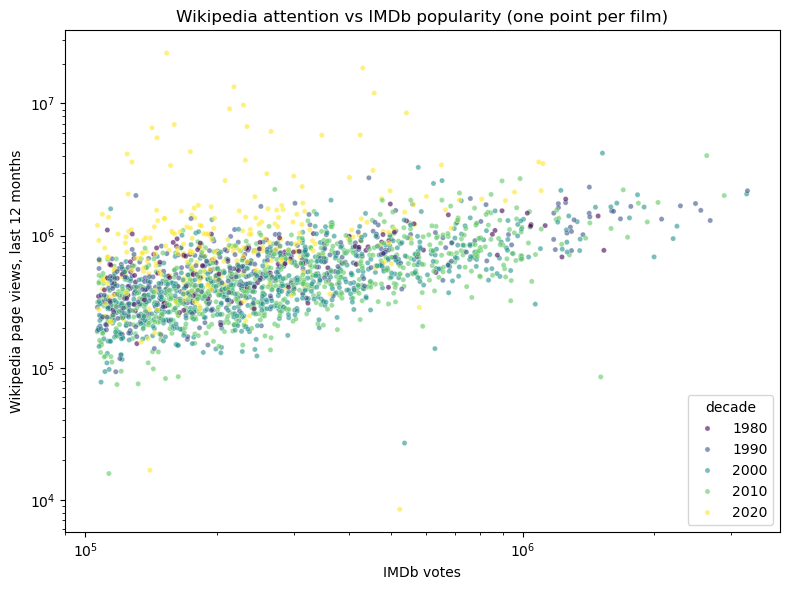

In [5]:
def spearman_sql(group_expr, where=""):
    return f'''
    WITH base AS (SELECT *, {group_expr} AS grp FROM attention {where}),
    ranked AS (
        SELECT grp,
               PERCENT_RANK() OVER (PARTITION BY grp ORDER BY numVotes) AS r_votes,
               PERCENT_RANK() OVER (PARTITION BY grp ORDER BY views_12m) AS r_views,
               PERCENT_RANK() OVER (PARTITION BY grp ORDER BY article_bytes) AS r_bytes,
               PERCENT_RANK() OVER (PARTITION BY grp ORDER BY sitelinks) AS r_sitelinks,
               PERCENT_RANK() OVER (PARTITION BY grp ORDER BY averageRating) AS r_rating,
               views_per_1k_votes, article_bytes, sitelinks, views_12m, numVotes
        FROM base
    )
    SELECT grp, COUNT(*) AS films,
           ROUND(CORR(r_votes, r_views), 3) AS spearman_votes_views,
           ROUND(CORR(r_votes, r_bytes), 3) AS spearman_votes_article_size,
           ROUND(CORR(r_votes, r_sitelinks), 3) AS spearman_votes_languages,
           ROUND(CORR(r_rating, r_views), 3) AS spearman_rating_views,
           percentile(views_12m, 0.5) AS median_views_12m,
           percentile(numVotes, 0.5) AS median_votes,
           percentile(views_per_1k_votes, 0.5) AS median_views_per_1k_votes,
           percentile(article_bytes, 0.5) AS median_article_bytes,
           percentile(sitelinks, 0.5) AS median_languages
    FROM ranked GROUP BY grp HAVING COUNT(*) >= {MIN_GROUP_SIZE} ORDER BY grp
    '''


overall = export(spark.sql(spearman_sql("'all films'")), "overall_correlations.csv")  # Overall rank correlations between IMDb popularity and Wikipedia attention

fit = spark.sql('''
SELECT COVAR_POP(LOG10(numVotes), LOG10(views_12m)) / VAR_POP(LOG10(numVotes)) AS slope_views,
       AVG(LOG10(views_12m)) - COVAR_POP(LOG10(numVotes), LOG10(views_12m)) / VAR_POP(LOG10(numVotes)) * AVG(LOG10(numVotes)) AS intercept_views,
       COVAR_POP(LOG10(numVotes), LOG10(article_bytes)) / VAR_POP(LOG10(numVotes)) AS slope_bytes,
       AVG(LOG10(article_bytes)) - COVAR_POP(LOG10(numVotes), LOG10(article_bytes)) / VAR_POP(LOG10(numVotes)) * AVG(LOG10(numVotes)) AS intercept_bytes,
       POW(CORR(LOG10(numVotes), LOG10(views_12m)), 2) AS r2_views,
       POW(CORR(LOG10(numVotes), LOG10(article_bytes)), 2) AS r2_bytes
FROM attention
''').first().asDict()
fit_summary = pd.DataFrame([fit]).round(3)  # Log-log fit of Wikipedia views and article size on IMDb votes
display(fit_summary)
fit_summary.to_csv(OUTPUT_DIR / "loglog_fit.csv", index=False)

spark.sql(f'''
SELECT *,
       ROUND(LOG10(views_12m) - ({fit["intercept_views"]} + {fit["slope_views"]} * LOG10(numVotes)), 3) AS views_residual,
       ROUND(LOG10(article_bytes) - ({fit["intercept_bytes"]} + {fit["slope_bytes"]} * LOG10(numVotes)), 3) AS article_residual
FROM attention
''').cache().createOrReplaceTempView("attention_scored")

plot_pdf = spark.table("attention_scored").select("numVotes", "views_12m", "decade").toPandas()
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=plot_pdf, x="numVotes", y="views_12m", hue="decade", palette="viridis", s=14, alpha=0.6, ax=ax)
ax.set(xscale="log", yscale="log", xlabel="IMDb votes", ylabel="Wikipedia page views, last 12 months",
       title="Wikipedia attention vs IMDb popularity (one point per film)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "views_vs_votes.png", dpi=120)
plt.show()

### 5.2 By genre and by decade

,genre,films,spearman_votes_views,spearman_votes_article_size,spearman_votes_languages,spearman_rating_views,median_views_12m,median_votes,median_views_per_1k_votes,median_article_bytes,median_languages
0,Horror,260,0.544,0.474,0.629,0.427,536869.5,193807.5,2399.545,45406.5,39.0
1,History,66,0.579,0.659,0.696,0.266,503028.5,190817.0,2311.390,54229.5,46.0
2,Family,108,0.650,0.653,0.803,0.497,533591.5,206540.0,2108.665,58808.0,47.0
3,Mystery,270,0.547,0.465,0.702,0.266,492557.5,212477.0,2097.580,38418.5,39.0
4,Drama,942,0.588,0.428,0.687,0.322,516360.5,227555.5,2057.080,46164.0,44.0
5,War,39,0.425,0.596,0.769,0.236,757213.0,228572.0,1969.980,53728.0,49.0
6,Sport,43,0.394,0.211,0.541,0.338,412584.0,196911.0,1933.830,37926.0,36.0
7,Animation,177,0.493,0.458,0.635,0.540,477240.0,232864.0,1925.930,78268.0,59.0
8,Biography,165,0.607,0.350,0.663,0.354,417721.0,194254.0,1917.340,49886.0,44.0
9,Romance,245,0.510,0.467,0.677,0.304,447423.0,203587.0,1910.070,38228.0,44.0


,decade,films,spearman_votes_views,spearman_votes_article_size,spearman_votes_languages,spearman_rating_views,median_views_12m,median_votes,median_views_per_1k_votes,median_article_bytes,median_languages
0,1980,151,0.597,0.507,0.610,0.507,555318.0,193715.0,2441.440,54118.0,49.0
1,1990,328,0.697,0.521,0.765,0.468,532416.5,217444.5,2058.525,42817.5,47.0
2,2000,620,0.657,0.532,0.723,0.357,425532.0,258143.5,1516.910,41903.0,47.0
3,2010,700,0.650,0.558,0.725,0.473,458504.5,266246.0,1608.945,52473.5,45.0
4,2020,291,0.382,0.517,0.580,0.111,770571.0,194651.0,3664.960,70874.0,38.0


,genre,films,pct_much_more_viewed,pct_much_less_viewed,mean_views_residual,mean_article_residual
0,History,66,4.5,0.0,0.080,0.061
1,Horror,260,5.4,0.8,0.076,0.005
2,War,39,5.1,2.6,0.059,-0.050
3,Sport,43,4.7,0.0,0.020,-0.056
4,Thriller,409,4.4,1.2,0.019,-0.080
5,Drama,942,2.0,1.8,0.019,-0.031
6,Adventure,625,3.0,0.2,0.015,0.128
7,Mystery,270,4.1,3.0,0.014,-0.098
8,Sci-Fi,274,2.9,0.7,0.010,0.072
9,Family,108,0.0,0.0,0.009,0.087


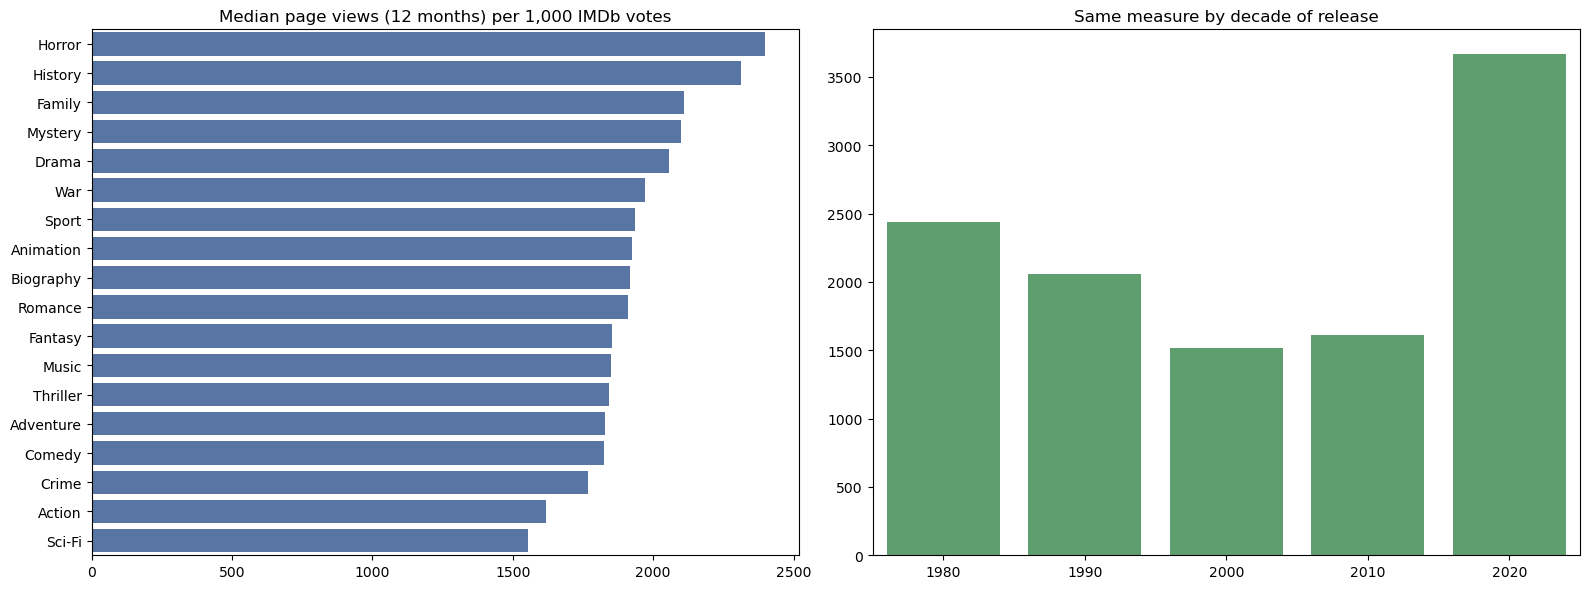

In [6]:
genre_comparison = export(  # Wikipedia attention relative to IMDb popularity, by genre
    spark.sql(spearman_sql("genre", "LATERAL VIEW explode(genres) g AS genre"))
    .withColumnRenamed("grp", "genre").orderBy(F.desc("median_views_per_1k_votes")),
    "by_genre.csv", n=30,
)
decade_comparison = export(  # Wikipedia attention relative to IMDb popularity, by decade of release
    spark.sql(spearman_sql("decade")).withColumnRenamed("grp", "decade"),
    "by_decade.csv",
)
outlier_share = export(  # Share of films far above or below the expected Wikipedia attention, by genre
    spark.sql(f'''
    SELECT genre, COUNT(*) AS films,
           ROUND(100 * AVG(CASE WHEN views_residual > {OUTLIER_RESIDUAL} THEN 1 ELSE 0 END), 1) AS pct_much_more_viewed,
           ROUND(100 * AVG(CASE WHEN views_residual < -{OUTLIER_RESIDUAL} THEN 1 ELSE 0 END), 1) AS pct_much_less_viewed,
           ROUND(AVG(views_residual), 3) AS mean_views_residual,
           ROUND(AVG(article_residual), 3) AS mean_article_residual
    FROM attention_scored LATERAL VIEW explode(genres) g AS genre
    GROUP BY genre HAVING COUNT(*) >= {MIN_GROUP_SIZE}
    ORDER BY mean_views_residual DESC
    '''),
    "outlier_share_by_genre.csv", n=30,
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.barplot(data=genre_comparison, y="genre", x="median_views_per_1k_votes", color="#4C72B0", ax=axes[0])
axes[0].set(title="Median page views (12 months) per 1,000 IMDb votes", xlabel="", ylabel="")
sns.barplot(data=decade_comparison, x="decade", y="median_views_per_1k_votes", color="#55A868", ax=axes[1])
axes[1].set(title="Same measure by decade of release", xlabel="", ylabel="")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "attention_by_genre_and_decade.png", dpi=120)
plt.show()

### 5.3 Films that don't fit the pattern

In [7]:
COLUMNS = ["primaryTitle", "startYear", F.concat_ws(",", "genres").alias("genres"), "numVotes", "averageRating", "views_12m",
           "views_per_1k_votes", "views_residual", "article_bytes", "sitelinks", "wikipedia_url"]

more_viewed = export(  # Films viewed on Wikipedia far more than their IMDb popularity predicts
    spark.table("attention_scored").orderBy(F.desc("views_residual")).select(*COLUMNS).limit(25),
    "much_more_viewed_than_expected.csv", n=25,
)
less_viewed = export(  # Films viewed on Wikipedia far less than their IMDb popularity predicts
    spark.table("attention_scored").orderBy("views_residual").select(*COLUMNS).limit(25),
    "much_less_viewed_than_expected.csv", n=25,
)
under_documented = export(  # Popular films (top quarter of votes) with the shortest articles relative to their popularity
    spark.sql('''
    WITH q AS (SELECT percentile(numVotes, 0.75) AS q3 FROM attention_scored)
    SELECT a.primaryTitle, a.startYear, concat_ws(',', a.genres) AS genres, a.numVotes, a.article_bytes, a.sitelinks, a.article_residual,
           a.views_12m, a.wikipedia_url, a.article_source_url
    FROM attention_scored a CROSS JOIN q
    WHERE a.numVotes >= q.q3
    ORDER BY a.article_residual
    LIMIT 25
    '''),
    "popular_but_under_documented.csv", n=25,
)

,primaryTitle,startYear,genres,numVotes,averageRating,views_12m,views_per_1k_votes,views_residual,article_bytes,sitelinks,wikipedia_url
0,Dhurandhar,2025,"Action,Crime,Thriller",153548,8.2,24050320,156630.63,1.796,123482,24,https://en.wikipedia.org/wiki/Dhurandhar
1,Avatar: Fire and Ash,2025,"Action,Adventure,Drama",218842,7.2,13362097,61058.19,1.461,166516,56,https://en.wikipedia.org/wiki/Avatar:_Fire_and_Ash
2,Obsession,2025,"Fantasy,Horror,Thriller",431052,7.8,18560180,43057.87,1.450,86258,52,https://en.wikipedia.org/wiki/Obsession_(2025_film)
3,Marty Supreme,2025,"Comedy,Drama,Sport",230053,7.5,9723866,42267.94,1.311,96876,34,https://en.wikipedia.org/wiki/Marty_Supreme
4,The Housemaid,2025,"Drama,Mystery,Thriller",213782,6.7,9119505,42657.96,1.300,39015,32,https://en.wikipedia.org/wiki/The_Housemaid_(2025_film)
5,Hamnet,2025,"Biography,Drama,History",142198,7.8,6554342,46093.07,1.249,51518,39,https://en.wikipedia.org/wiki/Hamnet_(film)
6,Zootopia 2,2025,"Adventure,Animation,Comedy",159831,7.3,6933961,43383.08,1.247,63309,63,https://en.wikipedia.org/wiki/Zootopia_2
7,One Battle After Another,2025,"Crime,Thriller",457705,7.6,11985308,26185.66,1.246,189878,54,https://en.wikipedia.org/wiki/One_Battle_After_Another
8,KPop Demon Hunters,2025,"Action,Adventure,Animation",146051,7.4,5497948,37644.03,1.167,194894,55,https://en.wikipedia.org/wiki/KPop_Demon_Hunters
9,Bugonia,2025,"Comedy,Crime,Sci-Fi",234365,7.4,6688294,28537.94,1.145,70003,39,https://en.wikipedia.org/wiki/Bugonia_(film)


,primaryTitle,startYear,genres,numVotes,averageRating,views_12m,views_per_1k_votes,views_residual,article_bytes,sitelinks,wikipedia_url
0,The Menu,2022,"Comedy,Horror,Thriller",523411,7.1,8482,16.21,-1.934,63677,34,https://en.wikipedia.org/wiki/The_Menu
1,Lost in Translation,2003,"Comedy,Drama",537026,7.7,26910,50.11,-1.439,139440,69,https://en.wikipedia.org/wiki/Lost_in_Translation
2,Sound of Freedom,2023,"Biography,Crime,Drama",140597,7.6,16752,119.15,-1.341,74161,33,https://en.wikipedia.org/wiki/Sound_of_Freedom
3,The Mountain II,2016,"Action,Drama,War",113301,8.1,15826,139.68,-1.317,5097,7,https://en.wikipedia.org/wiki/The_Mountain_II
4,Avengers: Endgame,2019,"Action,Adventure,Sci-Fi",1508009,8.4,85214,56.51,-1.172,49946,4,https://en.wikipedia.org/wiki/Avengers_Endgame:_Encore
5,Minority Report,2002,"Action,Crime,Mystery",630166,7.6,139615,221.55,-0.760,90435,57,https://en.wikipedia.org/wiki/Minority_Report
6,If I Stay,2014,"Comedy,Drama,Fantasy",132192,6.7,75545,571.48,-0.673,17742,37,https://en.wikipedia.org/wiki/If_I_Stay_(film)
7,Man on a Ledge,2012,"Action,Crime,Thriller",163231,6.6,85626,524.57,-0.666,15783,34,https://en.wikipedia.org/wiki/Man_on_a_Ledge
8,It's Kind of a Funny Story,2010,"Comedy,Drama,Romance",152599,7.1,82844,542.89,-0.665,18421,21,https://en.wikipedia.org/wiki/It%27s_Kind_of_a_Funny_Story_(film)
9,Ip Man 2,2010,"Action,Biography,Drama",118247,7.5,74668,631.46,-0.653,59253,32,https://en.wikipedia.org/wiki/Ip_Man_2


,primaryTitle,startYear,genres,numVotes,article_bytes,sitelinks,article_residual,views_12m,wikipedia_url,article_source_url
0,Snatch,2000,"Comedy,Crime",990605,23463,58,-0.635,674881,https://en.wikipedia.org/wiki/Snatch_(film),https://en.wikipedia.org/w/index.php?title=Snatch_(film)&oldid=1382997776
1,The Machinist,2004,"Drama,Thriller",448660,16548,43,-0.610,451024,https://en.wikipedia.org/wiki/The_Machinist,https://en.wikipedia.org/w/index.php?title=The_Machinist&oldid=1380517446
2,The Illusionist,2006,"Drama,Fantasy,Mystery",408123,17803,44,-0.557,313485,https://en.wikipedia.org/wiki/The_Illusionist_(2006_film),https://en.wikipedia.org/w/index.php?title=The_Illusionist_(2006_film)&oldid...
3,Ocean's Twelve,2004,"Crime,Thriller",444160,19809,51,-0.530,556405,https://en.wikipedia.org/wiki/Ocean%27s_Twelve,https://en.wikipedia.org/w/index.php?title=Ocean%27s_Twelve&oldid=1383838992
4,Prisoners,2013,"Crime,Drama,Mystery",968731,29592,42,-0.530,1624688,https://en.wikipedia.org/wiki/Prisoners_(2013_film),https://en.wikipedia.org/w/index.php?title=Prisoners_(2013_film)&oldid=13837...
5,"Lock, Stock and Two Smoking Barrels",1998,"Comedy,Crime",656968,24281,53,-0.529,458987,"https://en.wikipedia.org/wiki/Lock,_Stock_and_Two_Smoking_Barrels","https://en.wikipedia.org/w/index.php?title=Lock,_Stock_and_Two_Smoking_Barre..."
6,Now You See Me,2013,"Crime,Mystery,Thriller",781845,26961,52,-0.522,1201273,https://en.wikipedia.org/wiki/Now_You_See_Me_(film),https://en.wikipedia.org/w/index.php?title=Now_You_See_Me_(film)&oldid=13826...
7,The Pianist,2002,"Biography,Drama,Music",1031861,32557,78,-0.502,688698,https://en.wikipedia.org/wiki/The_Pianist_(2002_film),https://en.wikipedia.org/w/index.php?title=The_Pianist_(2002_film)&oldid=138...
8,Limitless,2011,"Sci-Fi,Thriller",657521,26181,42,-0.496,531775,https://en.wikipedia.org/wiki/Limitless_(film),https://en.wikipedia.org/w/index.php?title=Limitless_(film)&oldid=1367359688
9,The Bourne Supremacy,2004,"Action,Mystery,Thriller",520756,23414,59,-0.493,480010,https://en.wikipedia.org/wiki/The_Bourne_Supremacy_(film),https://en.wikipedia.org/w/index.php?title=The_Bourne_Supremacy_(film)&oldid...


### 5.4 Data used and lineage

Every value above can be traced: `pageviews_source_url` is the exact Pageviews API request, `article_source_url` is the article revision whose size was measured, and `sitelinks_source_url` is the Wikidata item.

In [8]:
coverage = pd.DataFrame([{  # How many enriched films could be used in the analysis
    "enriched_films_with_article": film_articles.count(),
    "films_with_page_views": spark.sql("SELECT COUNT(DISTINCT wikipedia_url) FROM pageviews").first()[0],
    "films_in_analysis": attention.count(),
    "films_with_language_count": attention.where("sitelinks IS NOT NULL").count(),
    "page_view_months": f"{first_month_12m}..{last_month}",
}])
display(coverage)
coverage.to_csv(OUTPUT_DIR / "coverage.csv", index=False)

spark.table("attention_scored").withColumn("genres", F.concat_ws(",", "genres")).toPandas().to_csv(OUTPUT_DIR / "film_attention_scores.csv", index=False)

,enriched_films_with_article,films_with_page_views,films_in_analysis,films_with_language_count,page_view_months
0,2090,2090,2090,2090,202511..202610


## 6. Key takeaways

*Fill in after the full run, from the tables above. Points to cover:*

1. **Overall strength:** the overall Spearman correlation between IMDb votes and 12-month page views, and the R² of the log-log fit. How much of Wikipedia attention does IMDb popularity explain?
2. **Genres:** which genres get the most and the least Wikipedia attention per IMDb vote (`by_genre.csv`), and whether rank correlations are weaker in some genres.
3. **Decades:** whether older films, despite fewer votes, are viewed more per vote than recent ones (lasting interest), or the reverse (recency).
4. **Outliers:** what the films far above the line have in common (franchises, controversies, anniversaries, remakes or sequels in the last 12 months), and the films far below it.
5. **Coverage gap:** popular films with short articles, and what they have in common (country, language, genre). These are candidates for better documentation on Wikipedia.